# The Keyboard Tax: results in one notebook

**What diacritic loss costs machine translation.** Course project, *Essentials in Text and Speech Processing*, University of Zurich.
Lucia Ivan, Karen Olivia Reyes Mendoza, Thomas Schurter.

This notebook wraps up the project: the idea, what we did, and every result with a short explanation.

**How to run it:** *Run All*. It takes a few seconds and needs only `pandas`, `numpy`, `matplotlib` and `pyyaml`
(the first code cell installs them if they are missing). No GPU, no model download, no dataset login:
the notebook reads the saved scores in `results/` and recomputes all statistics and charts from them.
The outputs are also stored in the file, so it can be read without running.

The full pipeline (translating 9,870 sentences with three systems) is described at the end.

## 1. The idea

People often type Portuguese without accents. What that does to a word depends on the word:

| | Example | Without the accent | What a reader sees |
|---|---|---|---|
| **Class A** | *não* (not) | *nao* is not a word | a typo, easy to repair |
| **Class B** | *país* (country) | *pais* is another word (parents) | a correct word with another meaning |

We translate Portuguese into English with three systems and ask four questions:

1. **RQ1** How much does removing all accents cost each system?
2. **RQ2** For the same amount of damage, does Class B cost more than Class A, and more than typos?
3. **RQ3** Do the usual scores notice the damage?
4. **RQ4** Which system copes best?

**Data.** 1,012 sentences from FLORES+ (`devtest`, Brazilian Portuguese with an English reference).
**Systems.** NLLB-200 (distilled, 600M), Opus-MT ROMANCE→en, and the LLM Qwen2.5-7B-Instruct. We train nothing.
**Scores.** COMET (main score, reacts to meaning), chrF and BLEU, plus a word-level check on a challenge set.

Each sentence is translated in up to five **versions**:

| Version | What is changed |
|---|---|
| `clean` | nothing |
| `stripped_100` | every accent removed |
| `a_only` | accents removed from *k* Class A words |
| `b_only` | accents removed from *k* Class B words (same *k*) |
| `noise` | keyboard typos, as many changed letters as in `b_only`, never a real word |

A **drop** is the score of the clean translation minus the score of the damaged one, for the same sentence
(positive = quality lost). All comparisons are paired by sentence and come with a 95% confidence interval (CI).

In [1]:
# Setup: find the repository, install the few packages if needed, load the saved scores.
import importlib.util
import subprocess
import sys
from pathlib import Path

missing = [p for p, m in [("pandas", "pandas"), ("numpy", "numpy"), ("matplotlib", "matplotlib"), ("pyyaml", "yaml")]
           if importlib.util.find_spec(m) is None]
if missing:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *missing], check=True)

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "results" / "scores.csv").exists()), None)
if ROOT is None:  # for example on Google Colab: get the repository first
    subprocess.run(["git", "clone", "-q", "https://github.com/karoli-rey/Keyboard_Tax"], check=True)
    ROOT = Path("Keyboard_Tax")
sys.path.insert(0, str(ROOT / "src"))

import pandas as pd
from IPython.display import Image, display

from keyboard_tax import analyze

RESULTS = ROOT / "results"
CHARTS = ROOT / "outputs" / "notebook"
CHARTS.mkdir(parents=True, exist_ok=True)
SYSTEMS = ["nllb", "opus_mt", "llm"]
NAMES = {"nllb": "NLLB", "opus_mt": "Opus-MT", "llm": "LLM (Qwen2.5)"}

scores = pd.read_csv(RESULTS / "scores.csv")            # one row per translation: chrF and COMET
counts = pd.read_csv(RESULTS / "version_counts.csv")    # per sentence and version: words and letters changed
corpus = pd.read_csv(RESULTS / "corpus_scores.csv")     # BLEU, chrF, COMET per version and system
print(f"{len(scores):,} scored translations = {scores['sent_id'].nunique():,} sentences, "
      f"{scores['system'].nunique()} systems, up to {scores['version'].nunique()} versions each")

9,870 scored translations = 1,012 sentences, 3 systems, up to 5 versions each


## 2. The data after our damage

How many sentences each version has, and how much was changed in it.

In [2]:
overview = counts.groupby("version").agg(
    sentences=("sent_id", "size"),
    class_a_words=("n_a", "mean"),
    class_b_words=("n_b", "mean"),
    letters_changed=("n_chars", "mean"),
).reindex(analyze.FIVE_VERSIONS).round(2)
display(overview)

,sentences,class_a_words,class_b_words,letters_changed
version,,,,
clean,1012,0.00,0.00,0.00
stripped_100,1012,2.65,0.63,3.94
a_only,422,1.27,0.00,1.35
b_only,422,0.00,1.27,1.28
noise,422,0.00,0.00,1.28


**Reading the table.** Removing every accent changes about 3.9 letters per sentence. `a_only`, `b_only` and `noise`
exist only for the **422 sentences** that contain both classes; each strips 1.27 words on average, so the three are
a fair comparison of *what kind* of damage, not *how much*. They are always compared with the clean translation of
the same 422 sentences.

## 3. RQ1: How much does removing all accents cost?

In [3]:
drops = analyze.drop_table(scores)          # paired drop per sentence, mean and 95% CI

def with_ci(row, metric="comet", scale=100):
    return (f"{row[f'{metric}_drop'] * scale:.2f}  "
            f"[{row[f'{metric}_low'] * scale:.2f}, {row[f'{metric}_high'] * scale:.2f}]")

everything = drops[(drops["subset"] == "all") & (drops["version"] == "stripped_100")].set_index("system")
clean = corpus[(corpus["subset"] == "all") & (corpus["version"] == "clean")].set_index("system")
stripped = corpus[(corpus["subset"] == "all") & (corpus["version"] == "stripped_100")].set_index("system")
rq1 = pd.DataFrame({
    "COMET clean": clean["comet"].round(3),
    "COMET drop x100 [95% CI]": everything.apply(with_ci, axis=1),
    "chrF drop [95% CI]": everything.apply(with_ci, axis=1, metric="chrf", scale=1),
    "BLEU clean": clean["bleu"].round(1),
    "BLEU, all accents removed": stripped["bleu"].round(1),
}).reindex(SYSTEMS).rename(index=NAMES)
display(rq1)

,COMET clean,COMET drop x100 [95% CI],chrF drop [95% CI],BLEU clean,"BLEU, all accents removed"
system,,,,,
NLLB,0.890,"1.10 [0.90, 1.30]","1.25 [0.90, 1.59]",48.2,46.5
Opus-MT,0.882,"2.24 [1.95, 2.53]","2.19 [1.89, 2.50]",45.2,41.8
LLM (Qwen2.5),0.891,"0.30 [0.17, 0.43]","0.60 [0.29, 0.91]",45.8,44.9


**What it shows.** All three systems translate clean text about equally well (COMET 0.88 to 0.89). Without accents
every system gets worse, and no confidence interval includes zero (**H1 supported**). The size differs a lot:
Opus-MT loses twice as much as NLLB, and the LLM loses about a quarter of what NLLB loses. In BLEU the loss is
0.9 to 3.4 points. The effect is real but small on average, because most sentences lose only harmless accents.

## 4. RQ2: Is Class B worse than Class A, and worse than typos?

Same sentences, same number of damaged words, three kinds of damage.

system,NLLB,Opus-MT,LLM (Qwen2.5)
version,,,
all removed,"1.58 [1.20, 1.96]","3.25 [2.74, 3.75]","0.50 [0.27, 0.72]"
Class A only,"0.25 [0.09, 0.40]","0.35 [0.17, 0.52]","0.05 [-0.03, 0.14]"
Class B only,"0.70 [0.45, 0.96]","1.73 [1.36, 2.09]","0.26 [0.13, 0.40]"
typos,"1.81 [1.45, 2.17]","4.37 [3.84, 4.91]","0.70 [0.45, 0.95]"


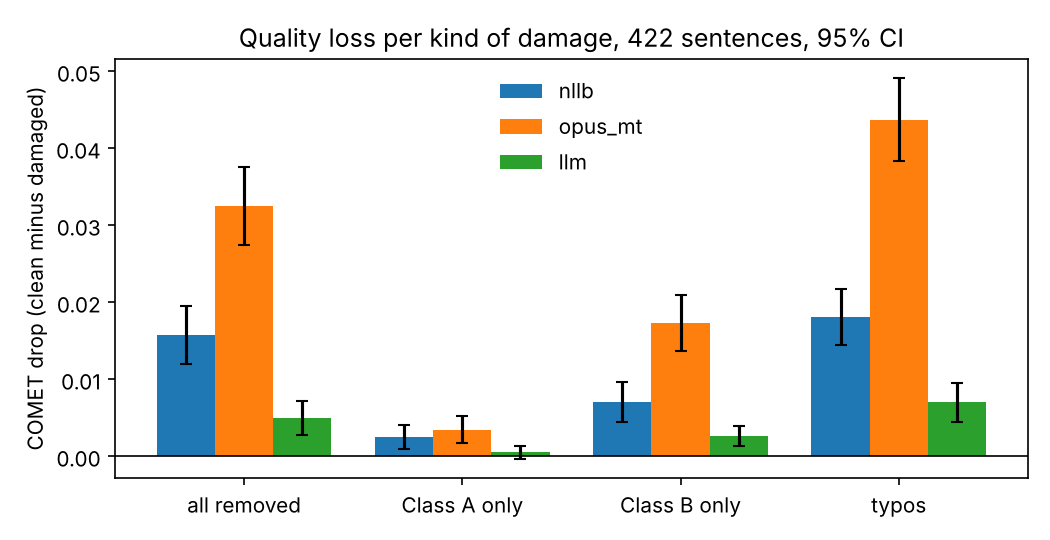

In [4]:
both = drops[drops["subset"] == "both_classes"]
table = both.assign(drop=both.apply(with_ci, axis=1)).pivot(index="version", columns="system", values="drop")
display(table.reindex(analyze.DAMAGED)[SYSTEMS].rename(columns=NAMES, index=analyze.VERSION_LABELS))

analyze.chart_drops(drops, CHARTS / "chart_drops.png")
display(Image(filename=str(CHARTS / "chart_drops.png"), width=640))

In [5]:
contrasts = analyze.contrast_table(scores)   # difference between two versions of the same sentence

def contrast_view(table):
    view = table.assign(diff=table.apply(
        lambda r: f"{r['comet_diff'] * 100:.2f}  [{r['comet_low'] * 100:.2f}, {r['comet_high'] * 100:.2f}]", axis=1))
    return view.pivot(index="contrast", columns="system", values="diff")[SYSTEMS].rename(columns=NAMES)

print("Difference in COMET drop x100 [95% CI], 422 sentences")
display(contrast_view(contrasts))

without_e = pd.read_csv(RESULTS / "contrasts_without_e.csv")
print(f"The same without the sentences where 'é' is the stripped Class B word ({int(without_e['n'].max())} sentences)")
display(contrast_view(without_e))

Difference in COMET drop x100 [95% CI], 422 sentences


system,NLLB,Opus-MT,LLM (Qwen2.5)
contrast,,,
b_only minus a_only,"0.46 [0.19, 0.73]","1.38 [0.98, 1.78]","0.21 [0.06, 0.36]"
b_only minus noise,"-1.10 [-1.51, -0.70]","-2.65 [-3.26, -2.03]","-0.44 [-0.71, -0.16]"
noise minus a_only,"1.56 [1.20, 1.93]","4.03 [3.49, 4.57]","0.65 [0.40, 0.90]"


The same without the sentences where 'é' is the stripped Class B word (240 sentences)


system,NLLB,Opus-MT,LLM (Qwen2.5)
contrast,,,
b_only minus a_only,"0.17 [-0.14, 0.48]","0.83 [0.34, 1.32]","-0.12 [-0.25, 0.00]"
b_only minus noise,"-1.36 [-1.85, -0.86]","-3.28 [-4.10, -2.47]","-0.63 [-0.90, -0.36]"
noise minus a_only,"1.53 [1.07, 1.99]","4.12 [3.45, 4.78]","0.51 [0.25, 0.77]"


**What it shows.**

- **Class B costs more than Class A** for every system (first row above zero): **H2 supported**. A missing accent
  that leaves a real word hurts more than one that leaves a non-word.
- **Much of this comes from one word.** *é* ("is") turns into *e* ("and") and is 240 of the 636 Class B words in the
  data. Without those sentences the difference holds only for Opus-MT (**H2b not supported** for NLLB and the LLM).
- **Typos cost more than Class B**, about 2.5 times more, for every system: **H3 not supported**. We expected the
  opposite. A likely reason: a word without its accent is a spelling the models have seen often, while a typo
  produces a form they have not.

## 5. The planned regression, and why it does not work

The proposal planned one regression per system:
drop = b0 + b1 · (Class B words) + b2 · (Class A words) + b3 · (letters changed).
We expected b1 > b2 and b3 near zero (H4).

system,NLLB,Opus-MT,LLM (Qwen2.5)
term,,,
b0 (constant),"0.0061 [0.0045, 0.0078]","0.0101 [0.0076, 0.0127]","0.0021 [0.0011, 0.0032]"
b1 (B words),"-0.0007 [-0.0033, 0.0019]","-0.0084 [-0.0124, -0.0045]","0.0001 [-0.0016, 0.0017]"
b2 (A words),"-0.0041 [-0.0061, -0.0020]","-0.0178 [-0.0213, -0.0142]","-0.0029 [-0.0045, -0.0013]"
b3 (changed letters),"0.0040 [0.0025, 0.0056]","0.0167 [0.0136, 0.0198]","0.0021 [0.0009, 0.0032]"


Correlation between 'Class A words' and 'letters changed': 0.88
Correlation between 'Class B words' and 'letters changed': 0.32


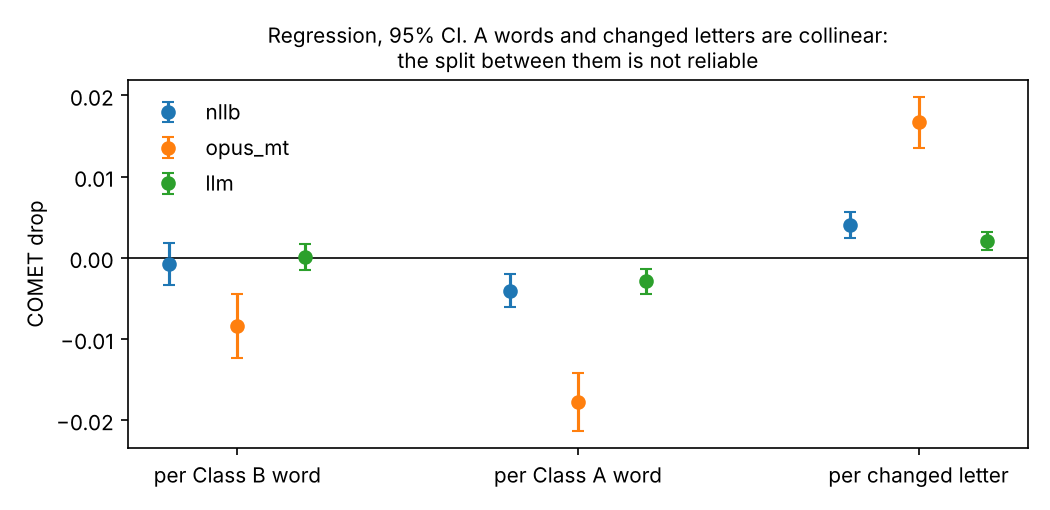

In [6]:
fit = analyze.regression(scores, counts)
view = fit[fit["metric"] == "comet"] if "metric" in fit else fit
view = view.assign(estimate=view.apply(
    lambda r: f"{r['estimate']:.4f}  [{r['low']:.4f}, {r['high']:.4f}]", axis=1))
display(view.pivot(index="term", columns="system", values="estimate")[SYSTEMS].rename(columns=NAMES))

damaged = counts[counts["version"] != "clean"]
print("Correlation between 'Class A words' and 'letters changed':", round(damaged["n_a"].corr(damaged["n_chars"]), 2))
print("Correlation between 'Class B words' and 'letters changed':", round(damaged["n_b"].corr(damaged["n_chars"]), 2))

analyze.chart_regression(fit, CHARTS / "chart_regression.png")
display(Image(filename=str(CHARTS / "chart_regression.png"), width=640))

**What it shows.** The estimate for a Class A word comes out *negative*, as if removing an accent improved the
translation, and the estimate for a changed letter is positive. That is not a finding. A stripped Class A word
almost always changes exactly one letter, so the two counts move together (correlation 0.88) and the regression
cannot tell them apart: it only shifts the same cost between two near-identical predictors (collinearity).
**H4 cannot be decided** with this model. The paired comparisons in section 4 answer the same question without this
problem, so they are our main test; the regression stays here because the proposal promised it.

## 6. RQ3: Do the scores notice? The challenge set

Average scores hide single wrong words, so we also check words directly. The challenge set has **187 items**
(170 sentences, 74 Class B words) where the lost accent changes the English meaning. Each item lists English words
for the right and for the wrong reading, for example *país*: right = country, nation; wrong = parents.
A translation is **right** if it has a right-reading word and no wrong one, **wrong** in the opposite case, and
**unclear** otherwise. Only items whose word really lost its accent are counted.

n  right  wrong  unclear  accuracy
system  version                                           
nllb    b_only        158    127     12       19     0.804
        clean         187    178      0        9     0.952
        stripped_100  187    156     13       18     0.834
opus_mt b_only        158    120     34        4     0.759
        clean         187    186      0        1     0.995
        stripped_100  187    141     40        6     0.754
llm     b_only        158    143      8        7     0.905
        clean         187    181      0        6     0.968
        stripped_100  187    170      9        8     0.909

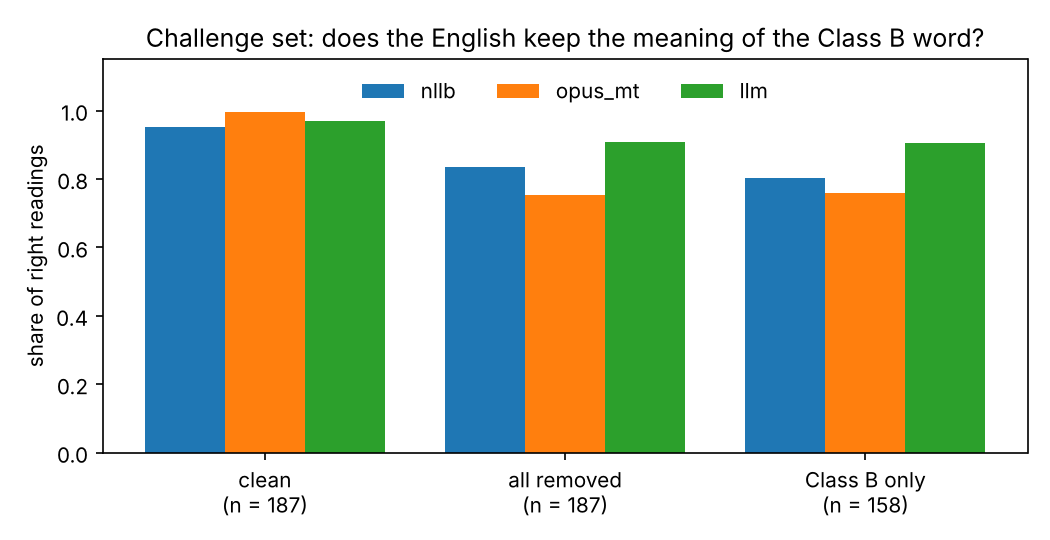

In [7]:
summary = pd.read_csv(RESULTS / "targeted_summary.csv")
display(summary.set_index(["system", "version"]).loc[SYSTEMS].round(3))

analyze.chart_targeted(summary, CHARTS / "chart_targeted.png")
display(Image(filename=str(CHARTS / "chart_targeted.png"), width=640))

In [8]:
bleu = pd.read_csv(RESULTS / "bleu_vs_targeted.csv").set_index("system").reindex(SYSTEMS)
def pct(x):
    return f"{x:.0%}"

h5 = pd.DataFrame({
    "right readings, clean": bleu["accuracy_clean"].map(pct),
    "right readings, all accents removed": bleu["accuracy_damaged"].map(pct),
    "right readings fall by [95% CI]": bleu.apply(
        lambda r: f"{r['accuracy_drop_share']:.0%}  [{r['accuracy_drop_low']:.0%}, {r['accuracy_drop_high']:.0%}]", axis=1),
    "BLEU falls by": bleu["bleu_drop_share"].map(pct),
    "chrF falls by": bleu["chrf_drop_share"].map(pct),
}).rename(index=NAMES)
print("The same 170 sentences, clean against all accents removed")
display(h5)

by_loss = pd.read_csv(RESULTS / "targeted_by_loss.csv")
kinds = by_loss[by_loss["version"].isin(["clean", "stripped_100"])]
items = kinds[(kinds["version"] == "clean") & (kinds["system"] == "nllb")].set_index("loss")["n"]
wide = kinds.pivot_table(index="loss", columns=["system", "version"], values="accuracy")[SYSTEMS].round(2)
wide.insert(0, ("items", ""), items)
print("Share of right readings by what the word loses (clean, then all accents removed)")
display(wide.sort_values("items", ascending=False))

The same 170 sentences, clean against all accents removed


,"right readings, clean","right readings, all accents removed",right readings fall by [95% CI],BLEU falls by,chrF falls by
system,,,,,
NLLB,95%,83%,"12% [7%, 17%]",5%,3%
Opus-MT,99%,75%,"24% [18%, 30%]",8%,4%
LLM (Qwen2.5),97%,91%,"6% [2%, 10%]",3%,1%


Share of right readings by what the word loses (clean, then all accents removed)


system     items  nllb              opus_mt                llm             
version          clean stripped_100   clean stripped_100 clean stripped_100
loss                                                                       
word class    93  0.96         0.92    1.00         0.95  0.96         0.96
meaning       55  0.95         0.76    1.00         0.51  0.98         0.95
tense         15  0.93         0.33    0.93         0.07  1.00         0.33
number        14  0.93         0.93    1.00         1.00  0.93         1.00
article        6  1.00         1.00    1.00         1.00  1.00         1.00
verb form      4  1.00         1.00    1.00         1.00  1.00         1.00

**What it shows.**

- On clean text the systems get 95 to 99% of the items right. Without accents Opus-MT falls to 75%, NLLB to 83%,
  the LLM to 91%.
- **BLEU hides this.** On the same sentences the share of right readings falls by 12% (NLLB) and 24% (Opus-MT),
  while BLEU falls by 5% and 8%: **H5 supported** for these two. For the LLM (6% against 3%) the difference is
  not certain.
- **The kind of loss decides.** Pairs that only change the word class (*análise* "analysis" / *analise* "analyzes",
  93 items) almost never fool a system: the context decides. Pairs that change the **meaning** (55 items) do:
  Opus-MT keeps only half of them. **Tense** pairs, mostly future verbs (*acontecerá* "will happen" /
  *acontecera* "had happened", 15 items), fail for every system, the LLM included.

Three translations of damaged sentences from our run:

| System | Portuguese (clean → damaged) | Translation of the damaged sentence |
|---|---|---|
| Opus-MT | causando as **marés** … uma **força** → *mares* … *forca* | "causing the **seas**, the Milky Way exerts a **gallows** over the galaxy" |
| NLLB | os animais que a jaguatirica **caça** → *caca* | "the animals that the jaguars **poop**" |
| LLM | rapidamente **desaparecerá** → *desaparecera* | "quickly **disappeared**" (the reference says "will rapidly evaporate") |

The last one costs only 0.02 COMET, although the tense is reversed.

## 7. RQ4: Which system copes best?

In [9]:
gaps = analyze.system_gap_table(scores)
display(gaps.round(4))

,version,systems,diff,low,high,n
0,stripped_100,llm minus nllb,-0.0080,-0.0102,-0.0057,1012
1,stripped_100,llm minus opus_mt,-0.0194,-0.0224,-0.0164,1012
2,stripped_100,nllb minus opus_mt,-0.0114,-0.0144,-0.0083,1012


**What it shows.** The LLM. Its drop after removing all accents is smaller than NLLB's by 0.80 COMET points (x100)
and smaller than Opus-MT's by 1.94, and both intervals exclude zero (**H6 supported**). It also keeps the most
right readings in the challenge set. Opus-MT, the smallest model, is the most fragile.

## 8. All hypotheses at a glance

We wrote the hypotheses down before seeing any result. The table is computed from the data above.

In [10]:
hypotheses = analyze.hypothesis_table(drops, contrasts, fit, gaps, without_e, bleu.reset_index())
verdict = hypotheses.assign(supported=hypotheses["supported"].map({True: "yes", False: "no"}))
display(verdict.pivot(index="hypothesis", columns="system", values="supported").fillna(""))

system,llm,llm vs nllb,llm vs opus_mt,nllb,opus_mt
hypothesis,,,,,
H1: removing all accents lowers quality,yes,,,yes,yes
H2: b_only costs more than a_only,yes,,,yes,yes
H2b: H2 without 'é',no,,,no,yes
H3: typos cost less than b_only,no,,,no,no
H4: b1 > b2 and b3 near zero,no,,,no,no
H5: BLEU hides the B damage,no,,,yes,yes
H6: the LLM loses less than the other systems,,yes,yes,,


*H4 shows "no" for every system, but as section 5 explains it cannot be decided with this model.*

## 9. What we learned

1. **Missing accents cost translation quality, but little on average.** The cost depends strongly on the system:
   the LLM is the most robust, the small Opus-MT model the least.
2. **Ambiguous losses (Class B) cost more than harmless ones (Class A)**, but most of that difference comes from
   the single word *é*.
3. **Typos are worse than missing accents**, against our expectation.
4. **Scores understate the damage.** When a word changes its meaning or its tense, the translation is wrong in a
   way BLEU barely registers; a word-level check shows it.
5. **The planned regression failed for a statistical reason** (collinearity). Paired comparisons replaced it.

**Limits.** One language pair. FLORES+ is formal text, while people drop accents mostly in informal writing.
The challenge set uses word matching, which leaves 3 to 10% of the damaged items unclear. Its items were drafted
with an AI assistant and reviewed for the Portuguese (see `notes/ai_use.md`).

## 10. How to reproduce everything

| Step | Command | Needs |
|---|---|---|
| 1 Load FLORES+ | `python -m keyboard_tax.data` | Hugging Face login (the dataset is gated) |
| 2 Label Class A / B | `python -m keyboard_tax.classify` | `scripts/get_dictionary.sh` |
| 3 Damaged versions | `python -m keyboard_tax.versions` | the reviewed `data/lexicon.csv` |
| 4 Translate | `python -m keyboard_tax.translate` | a GPU: `scripts/colab_gpu_run.ipynb` |
| 5 Score | `python -m keyboard_tax.score` | a GPU for COMET (same notebook) |
| 6 Analyze | `python -m keyboard_tax.analyze --save-results` | writes `outputs/6_results/` and `results/` |

`results/` holds numbers only. The sentences themselves stay behind the FLORES+ login, as its terms ask.
Settings are in `config.yaml`; what we release (word list, challenge set) is described in `data/README.md`;
how each part was built is in `notes/`.